####The objective of this study is to predict whether a customer will subscribe to a bank term deposit using historical bank marketing data. Logistic Regression, Decision Tree, K-Nearest Neighbours and Random Forest classifiers are trained and evaluated using accuracy, precision, recall, F1-score, confusion matrices and ROC-AUC. The models are compared to identify a suitable approach for improving marketing campaign targeting.

In [1]:
import pandas as pd

df = pd.read_csv("/content/bank-full.csv", sep=";")

print("Dataset shape:", df.shape)
display(df.head(10))

Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("bank-full.csv", sep=";")

# Display the first 10 rows
display(df.head(10))

# Display dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display column names and data types
print("\nDataset information:")
df.info()

# Display descriptive statistics
print("\nDescriptive statistics:")
display(df.describe(include="all").T)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


Number of rows: 45211
Number of columns: 17

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


####Data understanding and quality checks

In [3]:

# 1. Identify numerical and categorical columns
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_cols)

# 2. Check missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# 3. Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# 4. Check 'unknown' entries in categorical columns
print("\nUnknown entries per categorical column:")
for col in categorical_cols:
    count = (df[col].astype(str).str.lower() == "unknown").sum()
    if count > 0:
        print(f"{col}: {count}")

# 5. Inspect target distribution
print("\nTarget value counts:")
print(df["y"].value_counts())

print("\nTarget percentages:")
print((df["y"].value_counts(normalize=True) * 100).round(2))


Numerical columns:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']

Missing values per column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Number of duplicate rows: 0

Unknown entries per categorical column:
job: 288
education: 1857
contact: 13020
poutcome: 36959

Target value counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Target percentages:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


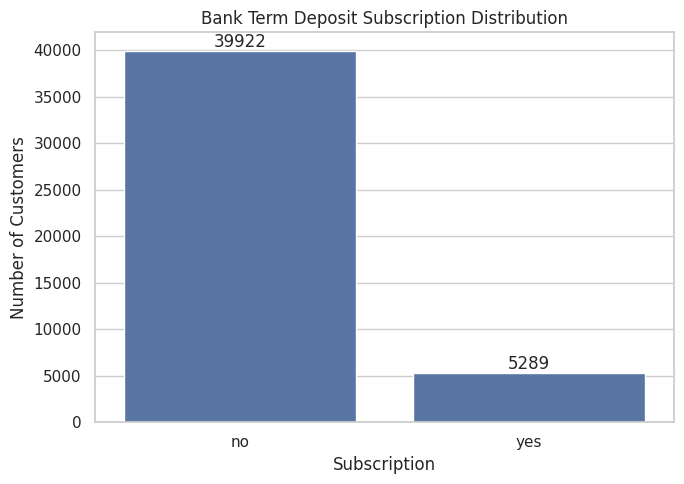

In [4]:

sns.set_theme(style="whitegrid")

target_counts = df["y"].value_counts().reindex(["no", "yes"])

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=target_counts.index, y=target_counts.values)

plt.title("Bank Term Deposit Subscription Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()


Subscription Counts and percentages

In [5]:

target_summary = df["y"].value_counts().reindex(["no", "yes"])

target_percentages = (
    df["y"].value_counts(normalize=True).reindex(["no", "yes"]) * 100
)

summary_df = pd.DataFrame({
    "Subscription": target_summary.index,
    "Count": target_summary.values,
    "Percentage": target_percentages.values.round(2)
})

display(summary_df)


,Subscription,Count,Percentage
0,no,39922,88.3
1,yes,5289,11.7


Subscription rate by customer job

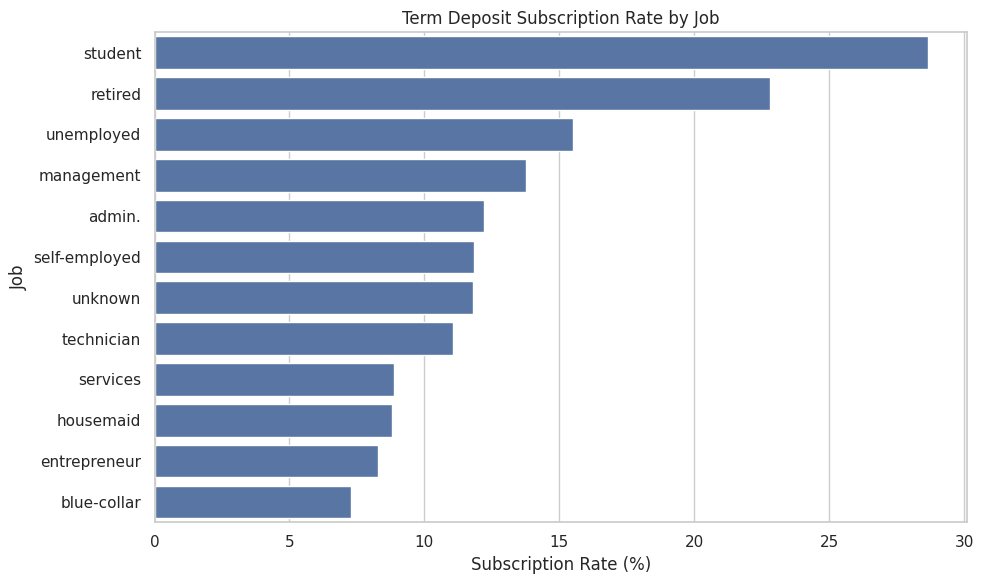

In [6]:

job_rates = (
    df.groupby("job", observed=True)["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=job_rates.values, y=job_rates.index)

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")
plt.tight_layout()
plt.show()


Subscription rate by education

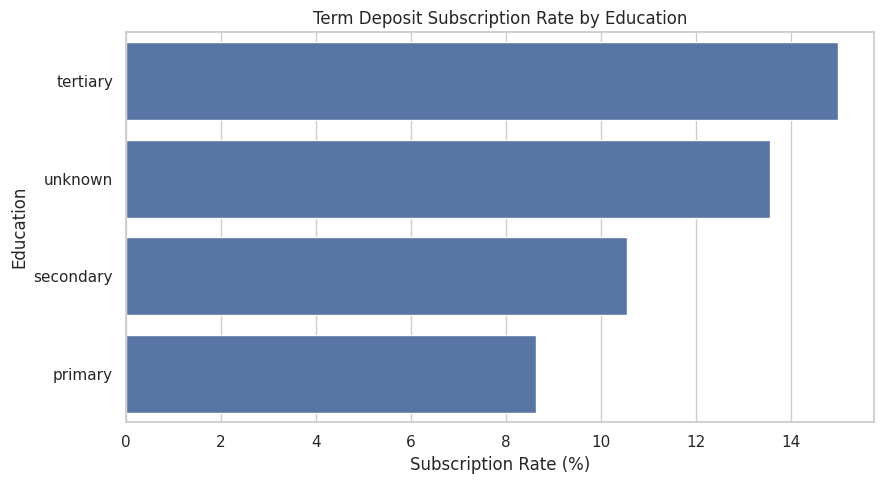

In [7]:

education_rates = (
    df.groupby("education", observed=True)["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=education_rates.values, y=education_rates.index)

plt.title("Term Deposit Subscription Rate by Education")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Education")
plt.tight_layout()
plt.show()


Subscription rate by previous campaign outcome

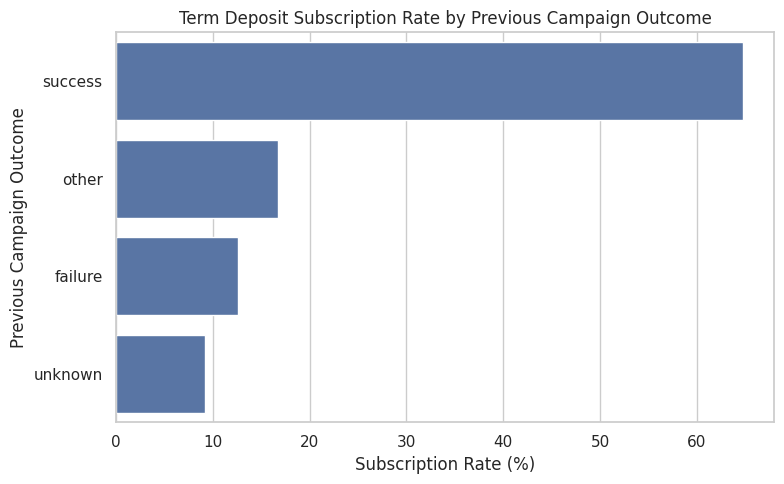

In [8]:

poutcome_rates = (
    df.groupby("poutcome", observed=True)["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=poutcome_rates.values, y=poutcome_rates.index)

plt.title("Term Deposit Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Previous Campaign Outcome")
plt.tight_layout()
plt.show()


Numerical attributes by subscription outcome

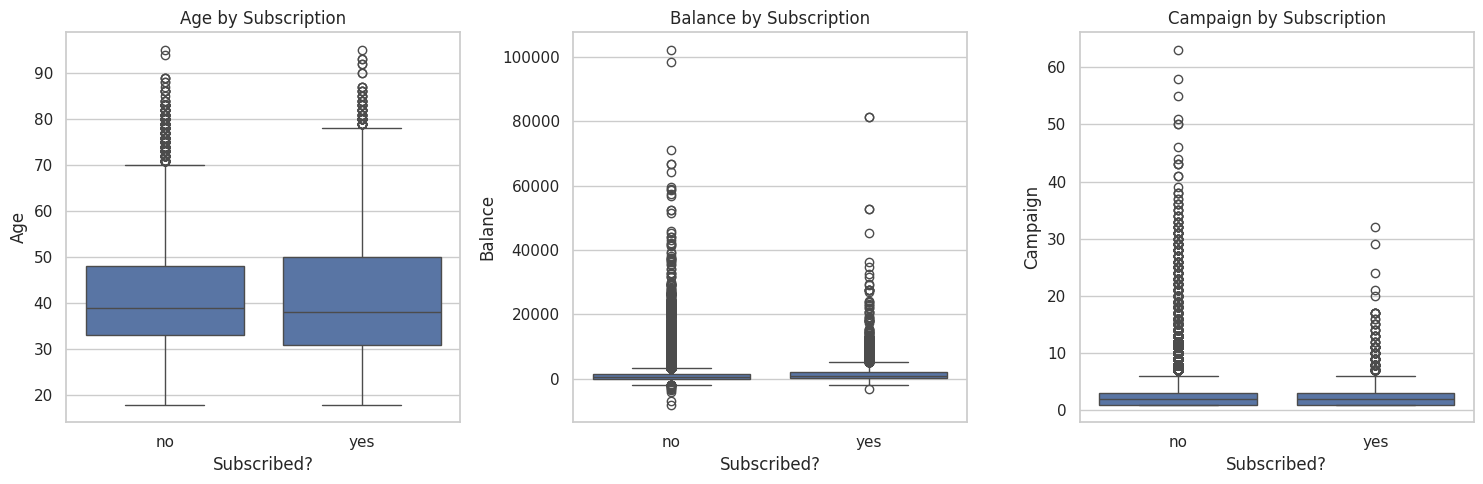

In [9]:

numeric_to_plot = ["age", "balance", "campaign"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, numeric_to_plot):
    sns.boxplot(data=df, x="y", y=col, ax=ax)
    ax.set_title(f"{col.capitalize()} by Subscription")
    ax.set_xlabel("Subscribed?")
    ax.set_ylabel(col.capitalize())

plt.tight_layout()
plt.show()


####Data preprocessing and train-test split

Prepare features and target

In [10]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Separate target and features
X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})

# Identify feature types after removing target and duration
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)
print("\nFeature count:", X.shape[1])
print("Target classes:\n", y.value_counts().rename(index={0: "no", 1: "yes"}))


Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Feature count: 15
Target classes:
 y
no     39922
yes     5289
Name: count, dtype: int64


Split the data

In [11]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(4))


Training samples: 36168
Testing samples: 9043

Training target proportions:
y
0    0.883
1    0.117
Name: proportion, dtype: float64

Testing target proportions:
y
0    0.883
1    0.117
Name: proportion, dtype: float64


Encode categorical features and scale numerical features

In [12]:

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline configured successfully.")


Preprocessing pipeline configured successfully.


####Train the four classification models

Define and train the models

In [13]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    )
}

trained_models = {}
results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"\n{name} trained successfully.")

results_df = pd.DataFrame(results).set_index("Model")
print("\nModel training completed!")
display(results_df.round(4))



Logistic Regression trained successfully.

Decision Tree trained successfully.

KNN trained successfully.

Random Forest trained successfully.

Model training completed!


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8933,0.6632,0.1786,0.2815,0.7717
Decision Tree,0.8309,0.2982,0.3289,0.3128,0.6132
KNN,0.8874,0.5529,0.1975,0.2911,0.7027
Random Forest,0.8954,0.6373,0.2457,0.3547,0.7888


Compare model performance

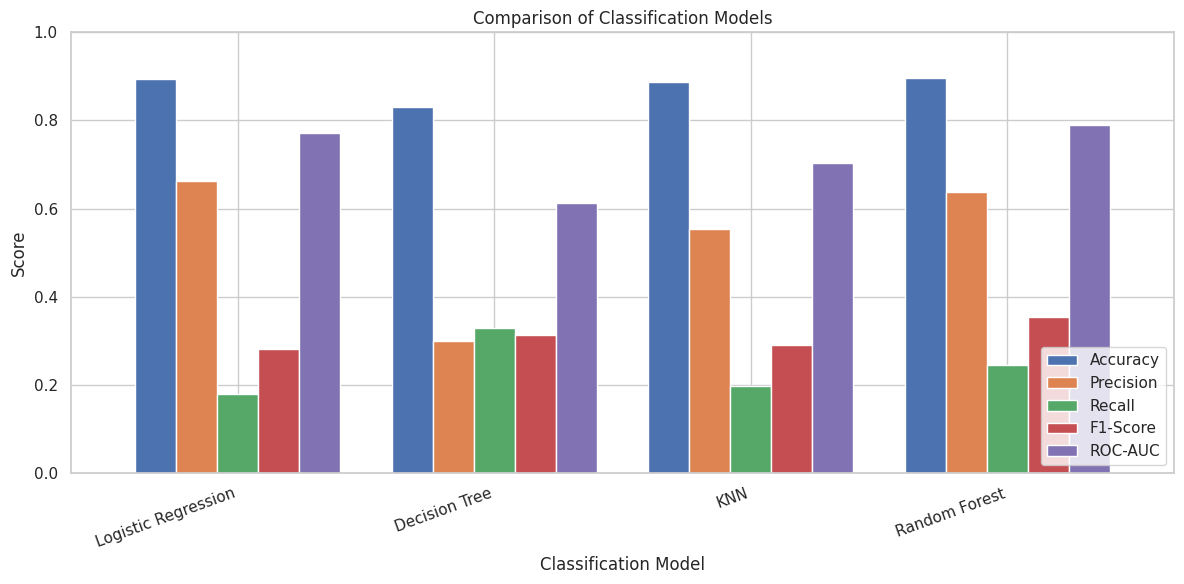

In [14]:

results_df.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("Comparison of Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


Generate classification reports

In [15]:

for name, pipeline in trained_models.items():
    y_pred = pipeline.predict(X_test)

    print(f"\n{'=' * 55}")
    print(name)
    print("=" * 55)

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No subscription", "Subscribed"],
        zero_division=0
    ))



Logistic Regression
                 precision    recall  f1-score   support

No subscription       0.90      0.99      0.94      7985
     Subscribed       0.66      0.18      0.28      1058

       accuracy                           0.89      9043
      macro avg       0.78      0.58      0.61      9043
   weighted avg       0.87      0.89      0.87      9043


Decision Tree
                 precision    recall  f1-score   support

No subscription       0.91      0.90      0.90      7985
     Subscribed       0.30      0.33      0.31      1058

       accuracy                           0.83      9043
      macro avg       0.60      0.61      0.61      9043
   weighted avg       0.84      0.83      0.83      9043


KNN
                 precision    recall  f1-score   support

No subscription       0.90      0.98      0.94      7985
     Subscribed       0.55      0.20      0.29      1058

       accuracy                           0.89      9043
      macro avg       0.73      0.59   

####Confusion matrices and ROC curves

Confusion matrices for all four models

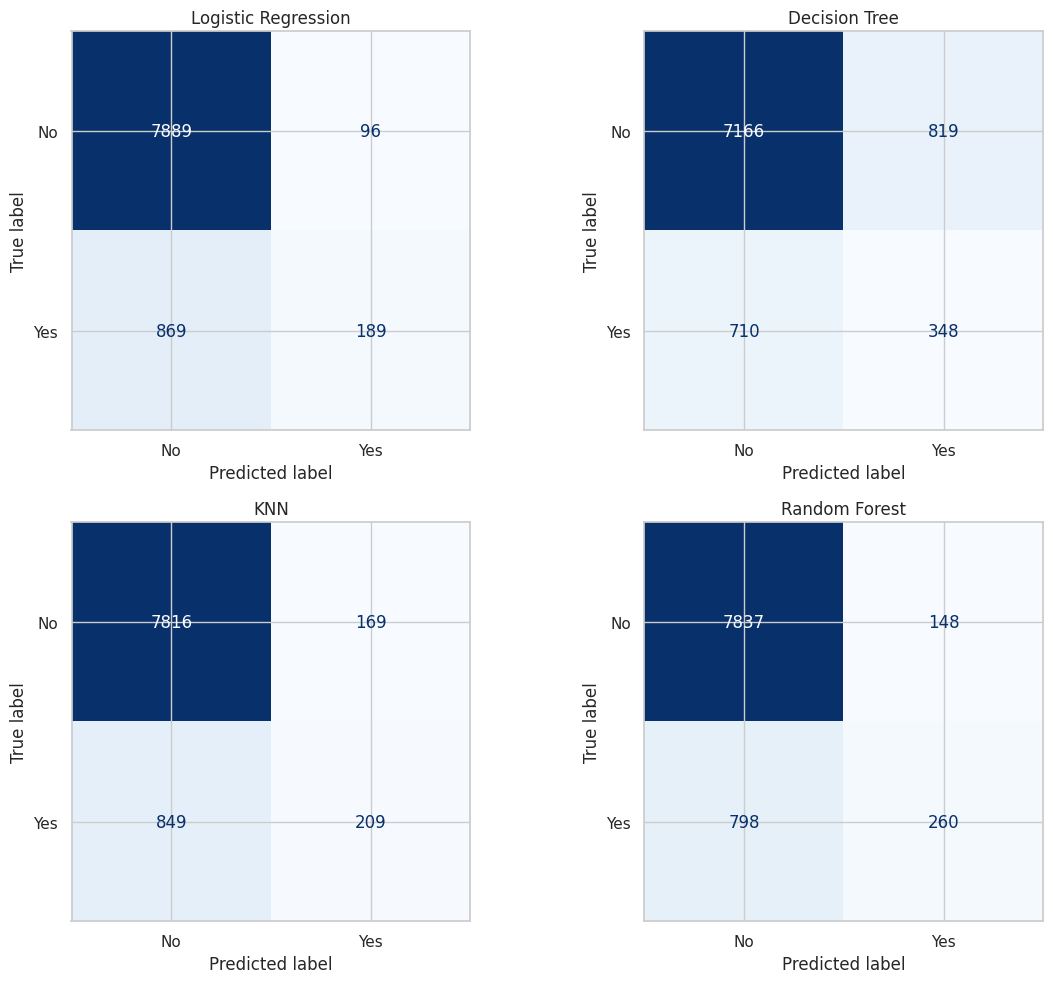

In [16]:

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, pipeline) in zip(axes, trained_models.items()):
    y_pred = pipeline.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["No", "Yes"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()


ROC curves and AUC

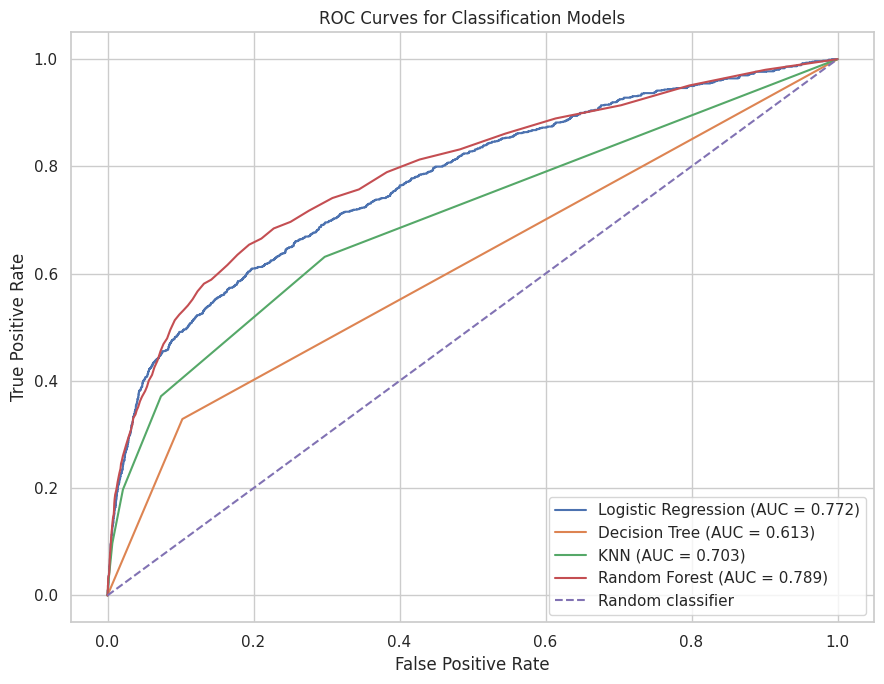

In [17]:

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(9, 7))

for name, pipeline in trained_models.items():
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.title("ROC Curves for Classification Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


Identify the leading model for each metric

In [18]:

print("Best model by each evaluation metric:\n")

for metric in results_df.columns:
    best_model = results_df[metric].idxmax()
    best_score = results_df.loc[best_model, metric]

    print(f"{metric}: {best_model} ({best_score:.4f})")

print("\nComplete comparison table:")
display(results_df.round(4))


Best model by each evaluation metric:

Accuracy: Random Forest (0.8954)
Precision: Logistic Regression (0.6632)
Recall: Decision Tree (0.3289)
F1-Score: Random Forest (0.3547)
ROC-AUC: Random Forest (0.7888)

Complete comparison table:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8933,0.6632,0.1786,0.2815,0.7717
Decision Tree,0.8309,0.2982,0.3289,0.3128,0.6132
KNN,0.8874,0.5529,0.1975,0.2911,0.7027
Random Forest,0.8954,0.6373,0.2457,0.3547,0.7888



## 1. What the Results Show

The following table summarizes the best-performing model for each evaluation metric.

| Metric | Best Model | Score |
|---|---|---:|
| Accuracy | Random Forest | 89.54% |
| Precision | Logistic Regression | 66.32% |
| Recall | Decision Tree | 32.89% |
| F1-score | Random Forest | 35.47% |
| ROC-AUC | Random Forest | 0.7888 |

*Note: These scores are based on the test-set results.*

## 2. Key Observations

- **Random Forest:** Achieved the highest accuracy (89.54%), F1-score (35.47%), and ROC-AUC (0.7888), making it the strongest overall model among the four based on these metrics.
- **Logistic Regression:** Achieved the highest precision (66.32%), meaning that its positive predictions were more likely to identify actual subscribers. However, its recall was only 17.86%.
- **Decision Tree:** Achieved the highest recall (32.89%), identifying a larger proportion of actual subscribers than the other models at the default classification threshold. Its precision was relatively low at 29.82%.
- **Class imbalance:** Since most customers did not subscribe, accuracy alone is insufficient to evaluate model effectiveness. Precision, recall, F1-score, and ROC-AUC provide additional insight into model performance.
- **Missed subscribers:** Random Forest had a recall of 24.57%, meaning it failed to identify many customers who actually subscribed.

## 3. Business Recommendation

Random Forest is a reasonable initial choice for predicting term-deposit subscriptions because it achieved the highest F1-score and ROC-AUC among the evaluated models. However, its recall of 24.57% indicates that many potential subscribers remain unidentified.

If the bank prioritizes identifying more potential subscribers, it should investigate adjusting the classification threshold to improve recall. The bank should also evaluate the trade-off between false positives and false negatives, considering the cost of contacting customers who do not subscribe against the opportunity cost of missing likely subscribers.


Final Model Evaluation Table

In [19]:

# Rank models by F1-score and ROC-AUC
final_comparison = results_df.sort_values(
    by="F1-Score", ascending=False
).copy()

final_comparison["F1 Rank"] = (
    final_comparison["F1-Score"]
    .rank(ascending=False, method="min")
    .astype(int)
)

display(final_comparison.round(4))

best_model_name = results_df["F1-Score"].idxmax()
print("Recommended initial model:", best_model_name)
print(
    "F1-score:",
    round(results_df.loc[best_model_name, "F1-Score"], 4)
)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,F1 Rank
Model,,,,,,
Random Forest,0.8954,0.6373,0.2457,0.3547,0.7888,1
Decision Tree,0.8309,0.2982,0.3289,0.3128,0.6132,2
KNN,0.8874,0.5529,0.1975,0.2911,0.7027,3
Logistic Regression,0.8933,0.6632,0.1786,0.2815,0.7717,4


Recommended initial model: Random Forest
F1-score: 0.3547
